In [1]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_squared_error as mse, r2_score, mean_absolute_error as mae
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK
from sklearn.preprocessing import MinMaxScaler
import torch.nn as nn
import random
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import torch.nn as nn

torch.set_default_dtype(torch.float64)
dtype = torch.get_default_dtype()
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('Data.csv',header=0)

In [3]:
df=df.drop(columns='id')

In [4]:
state_encoder=LabelEncoder()
type_encoder=LabelEncoder()
df['state']=state_encoder.fit_transform(df['state'])
df['type']=type_encoder.fit_transform(df['type'])

In [5]:
x = df.drop(columns='state')
y = df['state']
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=26)

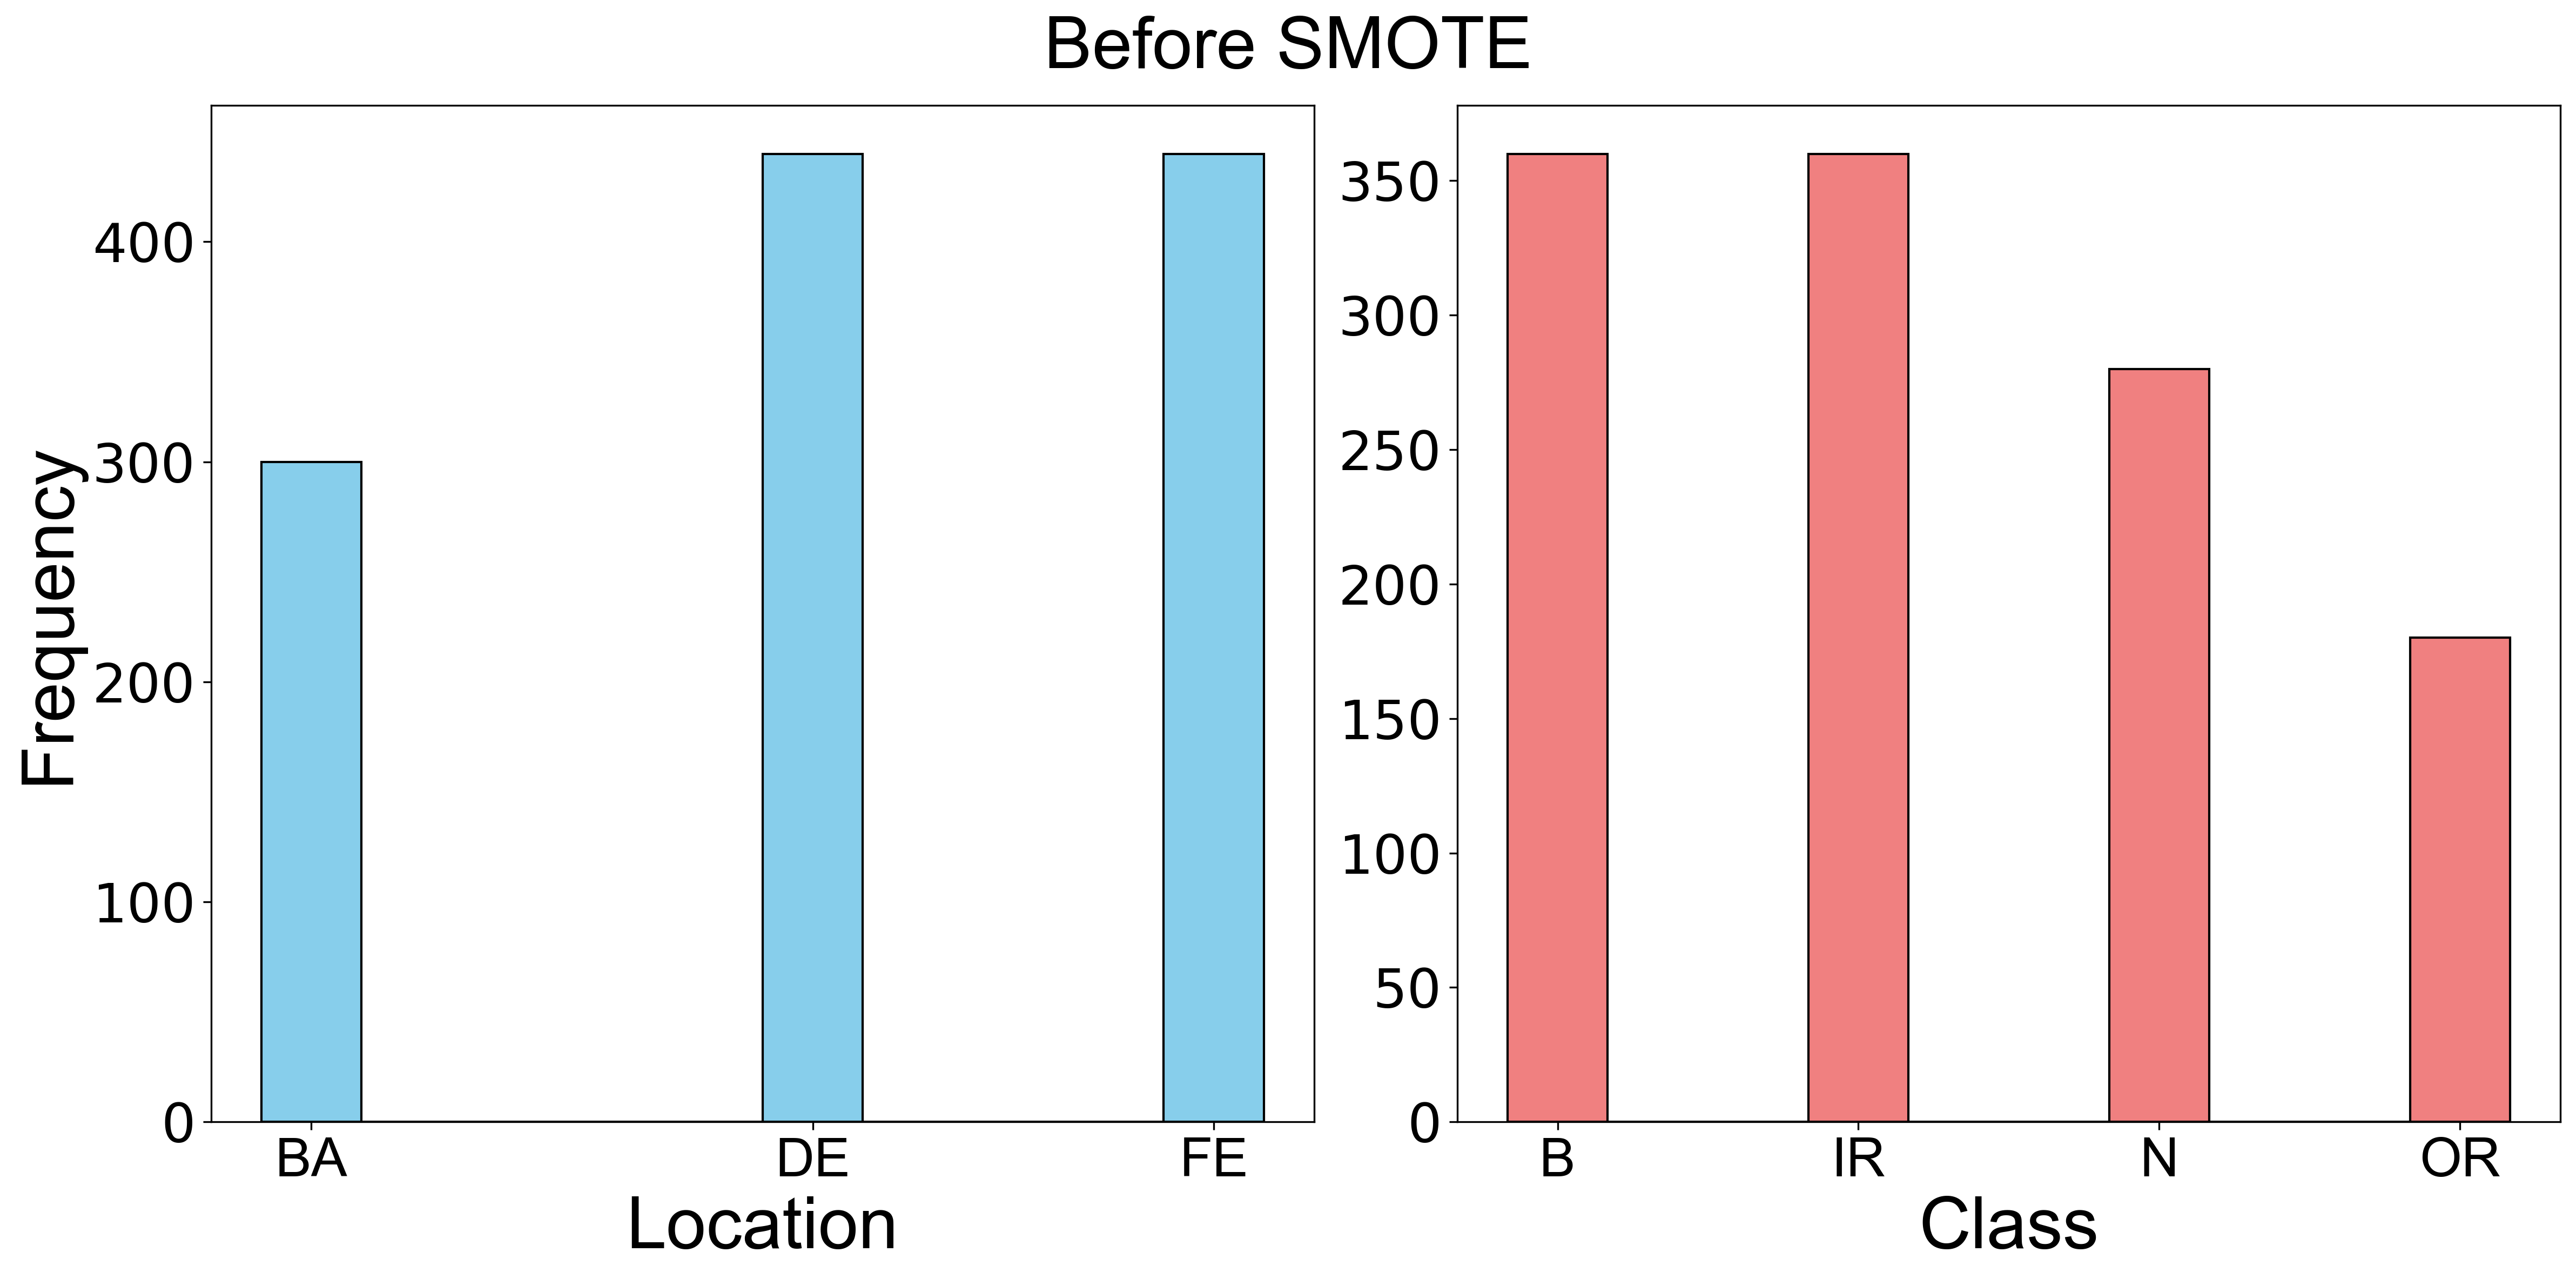

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('Before SMOTE', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(x['type'], color='skyblue', edgecolor='black')
axes[0].set_xlabel('Location', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.1, 1.1, 1.9])
axes[0].set_xticklabels(['BA', 'DE', 'FE'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95, 2.85])
axes[1].set_xticklabels(['B', 'IR', 'N', 'OR'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [7]:
x, y = smote.fit_resample(x, y)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=26)

In [8]:
random_indices = [57, 12, 140, 125, 114, 71, 52, 279, 44, 287,231,98,41,52,54]

# Iterate over the random indices and change their values to a random value from [0, 1, 2, 3]
for idx in random_indices:
    y_test.iloc[idx] = random.choice([0, 1, 2, 3])

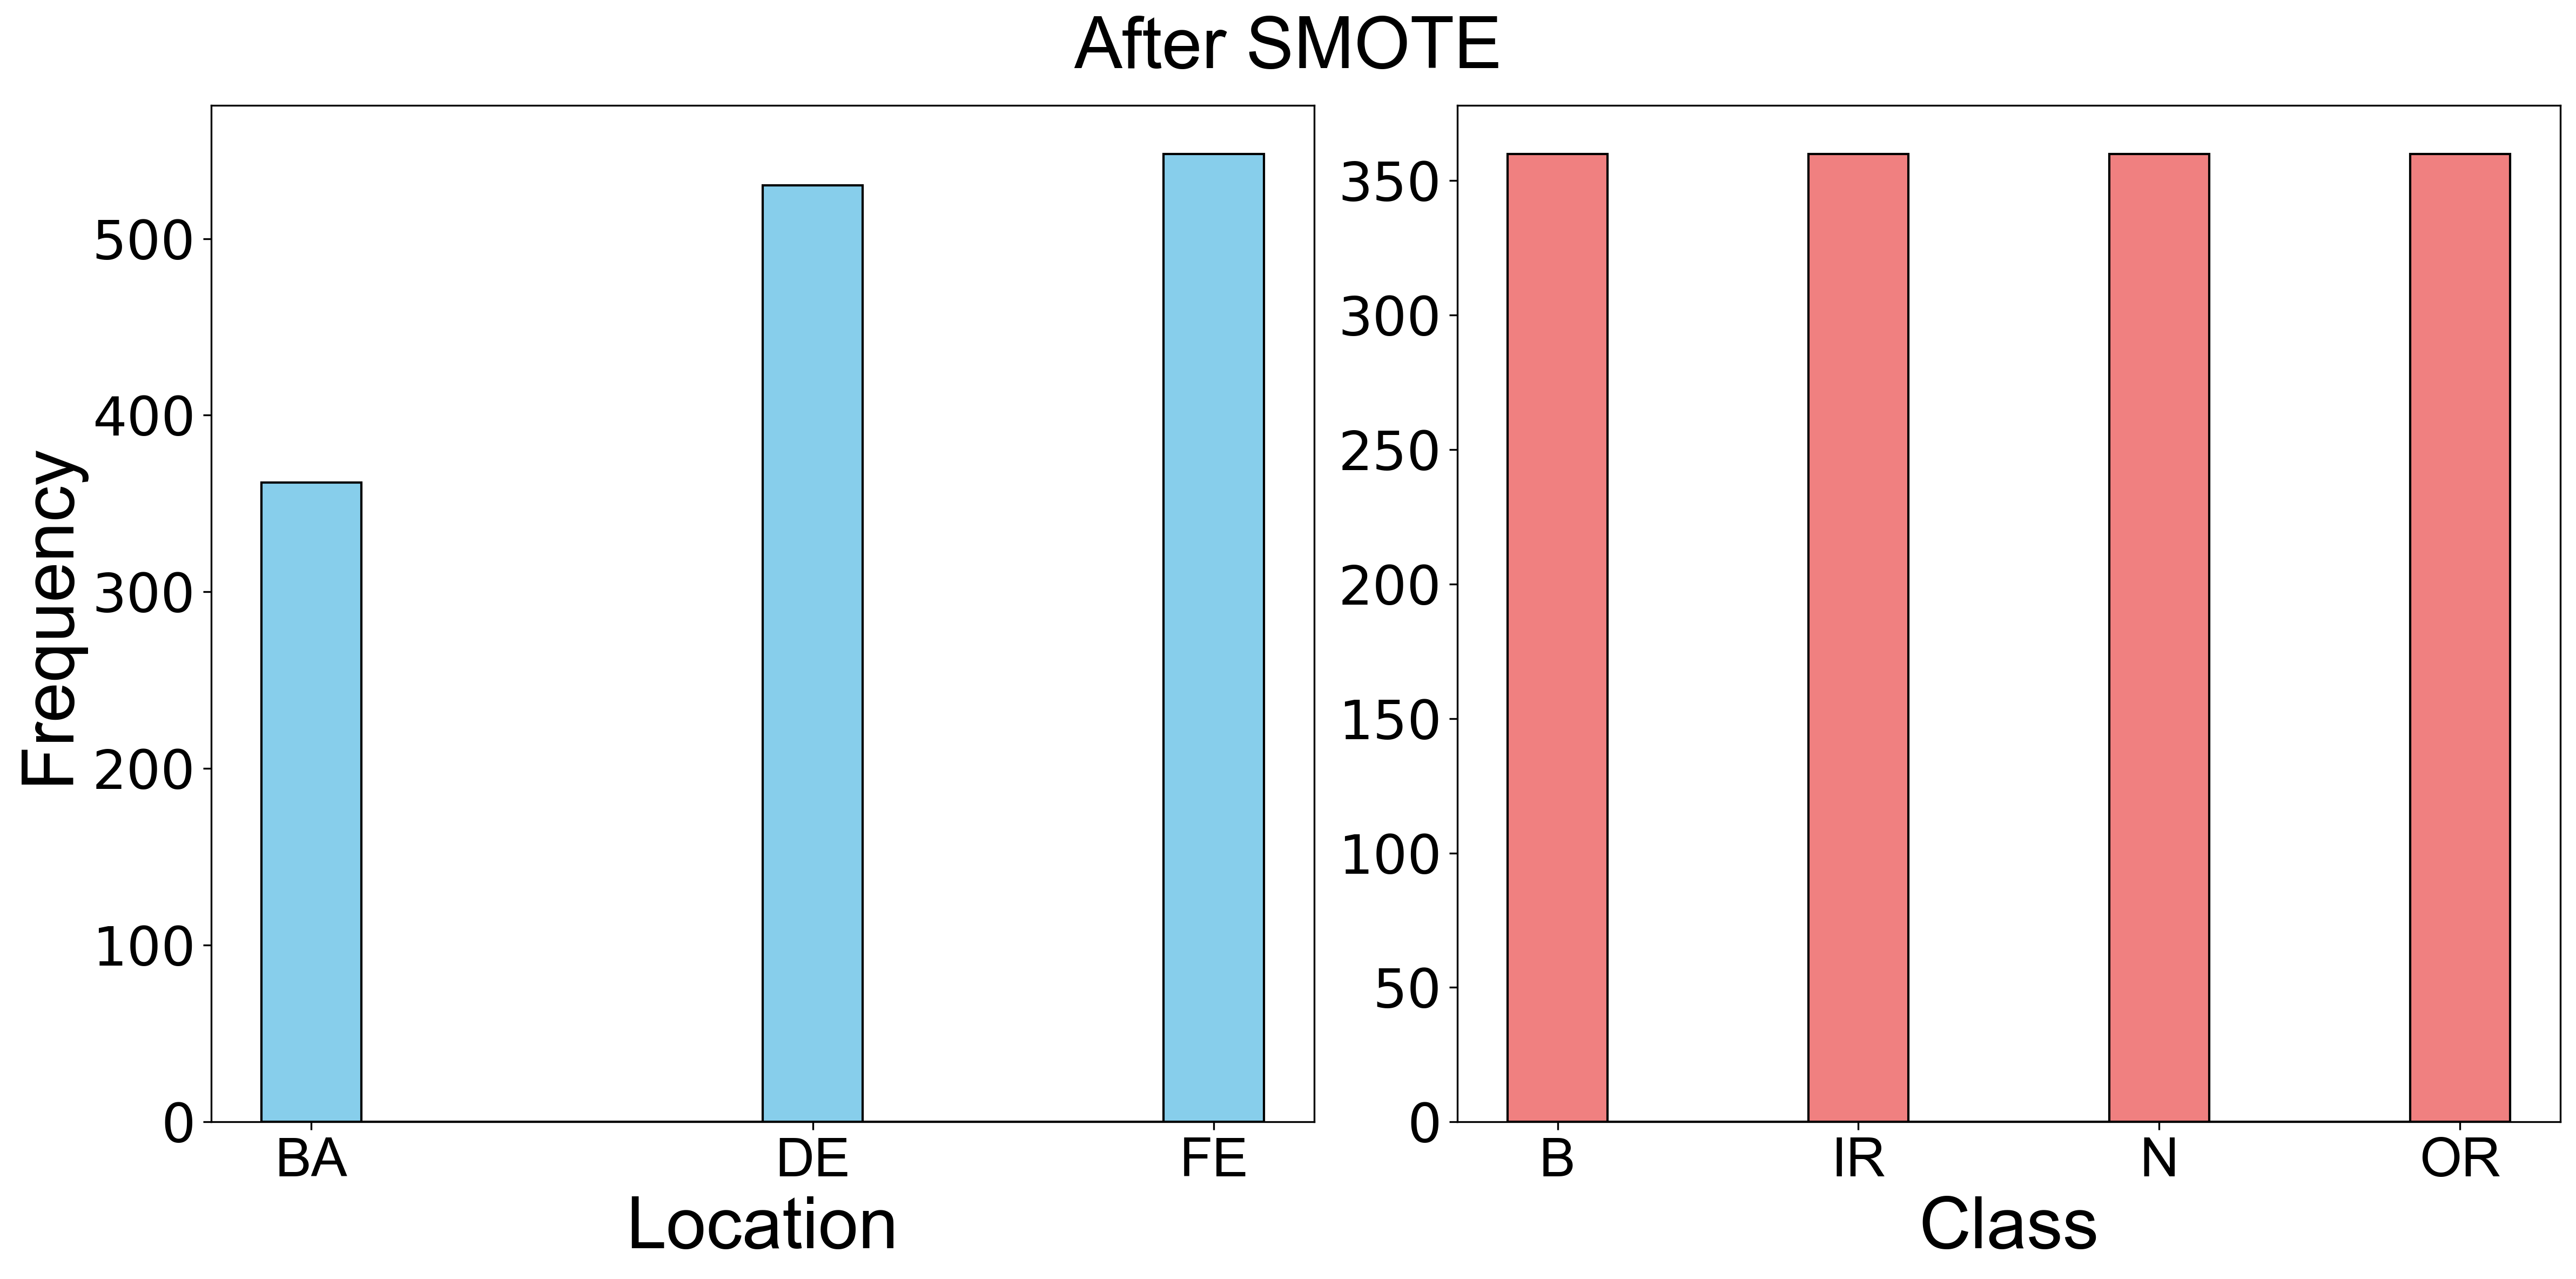

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('After SMOTE', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(x['type'], color='skyblue', edgecolor='black')
axes[0].set_xlabel('Location', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.1, 1.1, 1.9])
axes[0].set_xticklabels(['BA', 'DE', 'FE'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95, 2.85])
axes[1].set_xticklabels(['B', 'IR', 'N', 'OR'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

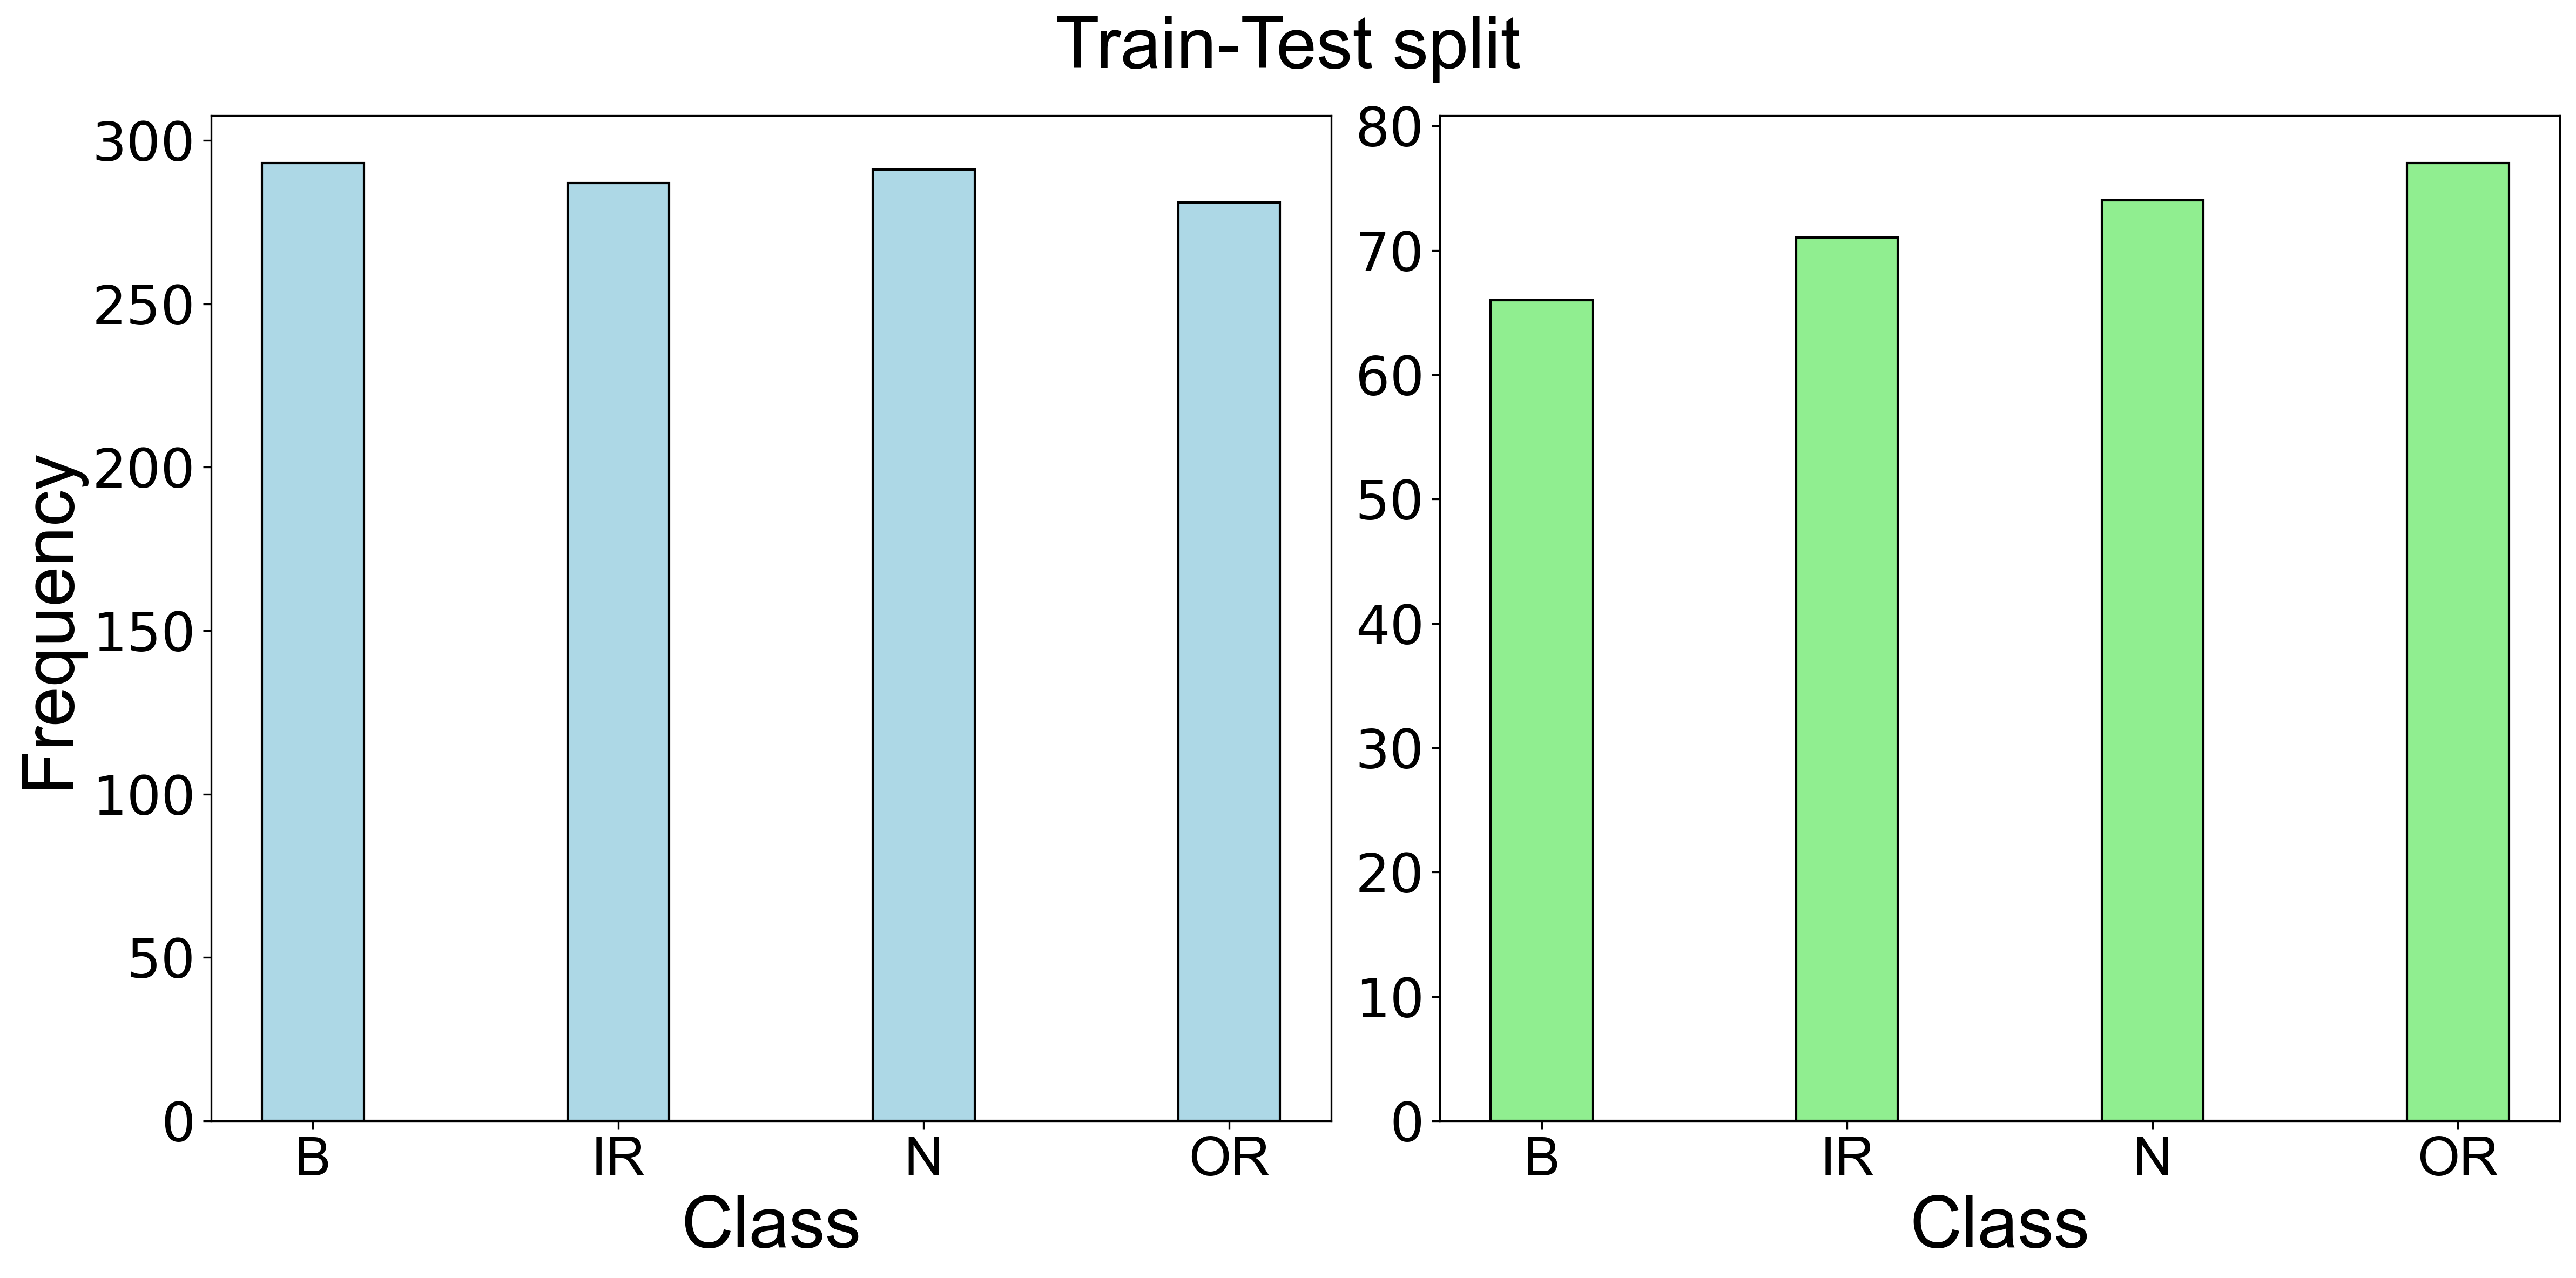

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)
plt.suptitle('Train-Test split', fontsize=32, family='Arial')

# Plot for x (Sensor location)
axes[0].hist(y_train, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Class', fontsize=32, family='Arial')
axes[0].set_ylabel('Frequency', fontsize=32, family='Arial')
axes[0].set_xticks([0.15, 1.05, 1.95, 2.85])
axes[0].set_xticklabels(['B', 'IR', 'N', 'OR'], fontsize=24, family='Arial')
axes[0].tick_params(axis='y', labelsize=24)

# Plot for y (Other sensor data)
axes[1].hist(y_test, color='lightgreen', edgecolor='black')
axes[1].set_xlabel('Class', fontsize=32, family='Arial')
axes[1].set_xticks([0.15, 1.05, 1.95, 2.85])
axes[1].set_xticklabels(['B', 'IR', 'N', 'OR'], fontsize=24, family='Arial')
axes[1].tick_params(axis='y', labelsize=24)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [11]:
dataset = {}
train_input=x_train.to_numpy()
train_label=y_train.to_numpy()
test_input=x_test.to_numpy()
test_label=y_test.to_numpy()

In [12]:
scaler_input = MinMaxScaler()

train_input_scaled = scaler_input.fit_transform(train_input)
test_input_scaled = scaler_input.transform(test_input)

dataset['train_input'] = torch.tensor(train_input_scaled, dtype=dtype)  # Convert to the specified dtype
dataset['test_input'] = torch.tensor(test_input_scaled, dtype=dtype)    # Convert to the specified dtype

# Reshape train_label and test_label to match the expected shape (for a classification task)
dataset['train_label'] = torch.tensor(train_label[:, None], dtype=dtype)  # Ensure shape is (n_samples, 1)
dataset['test_label'] = torch.tensor(test_label[:, None], dtype=dtype)    # Ensure shape is (n_samples, 1)

In [13]:
class CustomCNNClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, dense_units=64, dropout=0.5):
        super(CustomCNNClassifier, self).__init__()
        # Convolutional layers as provided:
        self.conv_layer1 = nn.Conv1d(in_channels=1, out_channels=4, kernel_size=3, stride=1)
        self.conv_layer2 = nn.Conv1d(in_channels=4, out_channels=8, kernel_size=3, stride=1)
        self.max_pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        
        self.conv_layer3 = nn.Conv1d(in_channels=8, out_channels=16, kernel_size=3, stride=1)
        self.conv_layer4 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, stride=1)
        self.max_pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        
        # Dynamically compute flattened feature dimension:
        dummy_input = torch.zeros(1, 1, input_dim)
        dummy_out = self._forward_conv(dummy_input)
        flattened_size = dummy_out.view(1, -1).shape[1]
        
        # Fully connected layers:
        self.fc1 = nn.Linear(flattened_size, dense_units)
        self.fc2 = nn.Linear(dense_units, num_classes)
        self.dropout = nn.Dropout(p=dropout)
        
    def _forward_conv(self, x):
        x = torch.relu(self.conv_layer1(x))
        x = torch.relu(self.conv_layer2(x))
        x = self.max_pool1(x)
        x = torch.relu(self.conv_layer3(x))
        x = torch.relu(self.conv_layer4(x))
        x = self.max_pool2(x)
        return x
        
    def forward(self, x):
        # x: (batch, input_dim) -> add channel dimension
        x = x.unsqueeze(1)
        x = self._forward_conv(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [14]:
space = {
    'dense_units': hp.quniform('dense_units', 32, 128, 16),
    'learning_rate': hp.loguniform('learning_rate', np.log(1e-5), np.log(1e-1)),
    'lambda_l2': hp.loguniform('lambda_l2', np.log(1e-7), np.log(1e-1))
}

In [15]:
def accuracy(predictions, labels):
    _, preds = torch.max(predictions, dim=1)
    correct = torch.sum(preds == labels).item()
    total = labels.size(0)
    return correct / total

In [16]:
param_df = pd.DataFrame(columns=['params', 'loss_curve_train', 'loss_curve_test', 
                                 'accuracy_curve_train', 'accuracy_curve_test', 'best_score'])
bestest_score = float('-inf')
trial_no = 0

# %%
def objective(params):
    global trial_no, bestest_score
    trial_no += 1
    params['dense_units'] = int(params['dense_units'])
    
    # Set device
    input_dim = dataset['train_input'].shape[1]
    num_classes = 4  # Classes: B, IR, N, OR
    
    model = CustomCNNClassifier(input_dim=input_dim,
                                num_classes=num_classes,
                                dense_units=params['dense_units'],
                                dropout=0.5)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'], weight_decay=params['lambda_l2'])
    
    num_epochs = 250
    patience = 100
    best_val_accuracy = float('-inf')
    epochs_no_improve = 0
    best_model_state = None
    
    training_loss = []
    test_loss = []
    training_acc = []
    test_acc = []
    
    train_input = dataset['train_input']
    train_label = dataset['train_label']
    test_input = dataset['test_input']
    test_label = dataset['test_label']
    
    for epoch in range(num_epochs):

        model.train()
        optimizer.zero_grad()
        predictions = model(train_input)
        loss = criterion(predictions, train_label.squeeze().long())
        preds_train = torch.argmax(torch.softmax(predictions, dim=1), dim=1)
        acc_train = accuracy_score(preds_train.cpu().numpy(), train_label.cpu().numpy())
        
        loss.backward()
        optimizer.step()
        
        training_loss.append(loss.item())
        training_acc.append(acc_train)
        
        # Evaluation on test set:
        model.eval()
        with torch.no_grad():
            val_predictions = model(test_input)
            val_loss = criterion(val_predictions, test_label.squeeze().long())
            preds_test = torch.argmax(torch.softmax(val_predictions, dim=1), dim=1)
            acc_test = accuracy_score(preds_test.cpu().numpy(), test_label.cpu().numpy())
            test_loss.append(val_loss.item())
            test_acc.append(acc_test)
            print(f"Epoch {epoch}: Train Acc: {acc_train:.4f}, Loss: {loss.item():.4f} ||| Test Acc: {acc_test:.4f}, Loss: {val_loss.item():.4f}")
        
        if acc_test > best_val_accuracy:
            best_val_accuracy = acc_test
            epochs_no_improve = 0
            best_model_state = model.state_dict()
        else:
            epochs_no_improve += 1
        
        if epochs_no_improve >= patience:
            model.load_state_dict(best_model_state)
            break
    
    if best_val_accuracy > bestest_score:
        bestest_score = best_val_accuracy
        torch.save({'model_state_dict': best_model_state, 'params': params}, "bestest_model.pth")
    
    model.eval()
    with torch.no_grad():
        final_predictions = model(test_input)
    final_acc = accuracy_score(torch.argmax(torch.softmax(final_predictions, dim=1), dim=1).cpu().numpy(),
                               test_label.cpu().numpy())
    param_df.loc[trial_no] = [params, training_loss, test_loss, training_acc, test_acc, final_acc]
    print("Final Test Accuracy:", final_acc)
    print("Params:", params)
    return -final_acc

In [17]:
trials = Trials()
best_params = fmin(fn=objective,
                   space=space,
                   algo=tpe.suggest,
                   max_evals=50,
                   trials=trials)

print("Best hyperparameters:", best_params)

Epoch 0: Train Acc: 0.2543, Loss: 1.3867 ||| Test Acc: 0.2674, Loss: 2.7310
Epoch 1: Train Acc: 0.2439, Loss: 2.8955 ||| Test Acc: 0.2569, Loss: 1.4233
Epoch 2: Train Acc: 0.2483, Loss: 1.4100 ||| Test Acc: 0.2465, Loss: 1.3920
Epoch 3: Train Acc: 0.2457, Loss: 1.3914 ||| Test Acc: 0.2292, Loss: 1.4369
Epoch 4: Train Acc: 0.2517, Loss: 1.4195 ||| Test Acc: 0.2569, Loss: 1.3966
Epoch 5: Train Acc: 0.2422, Loss: 1.3941 ||| Test Acc: 0.2292, Loss: 1.4555
Epoch 6: Train Acc: 0.2543, Loss: 1.4363 ||| Test Acc: 0.2569, Loss: 1.3865
Epoch 7: Train Acc: 0.2266, Loss: 1.3893 ||| Test Acc: 0.2674, Loss: 1.3890
Epoch 8: Train Acc: 0.2595, Loss: 1.4064 ||| Test Acc: 0.2674, Loss: 1.3858
Epoch 9: Train Acc: 0.2448, Loss: 1.3923 ||| Test Acc: 0.2465, Loss: 1.3884
Epoch 10: Train Acc: 0.2457, Loss: 1.3854 ||| Test Acc: 0.2465, Loss: 1.3941
Epoch 11: Train Acc: 0.2500, Loss: 1.3920 ||| Test Acc: 0.2292, Loss: 1.3933
Epoch 12: Train Acc: 0.2543, Loss: 1.3940 ||| Test Acc: 0.2292, Loss: 1.3913
Epoch 13:

In [18]:
param_df.to_csv('param_df_custom_CNN.csv')

In [19]:
checkpoint = torch.load("bestest_model.pth")
params_best = checkpoint['params']
input_dim = dataset['train_input'].shape[1]
num_classes = 4

model = CustomCNNClassifier(input_dim=input_dim,
                            num_classes=num_classes,
                            dense_units=int(params_best['dense_units']),
                            dropout=0.5)
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [20]:
model.eval()
with torch.no_grad():
    test_predictions = model(dataset['test_input'])

In [21]:
accuracy_score(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label)

0.9444444444444444

In [22]:
from sklearn.metrics import confusion_matrix


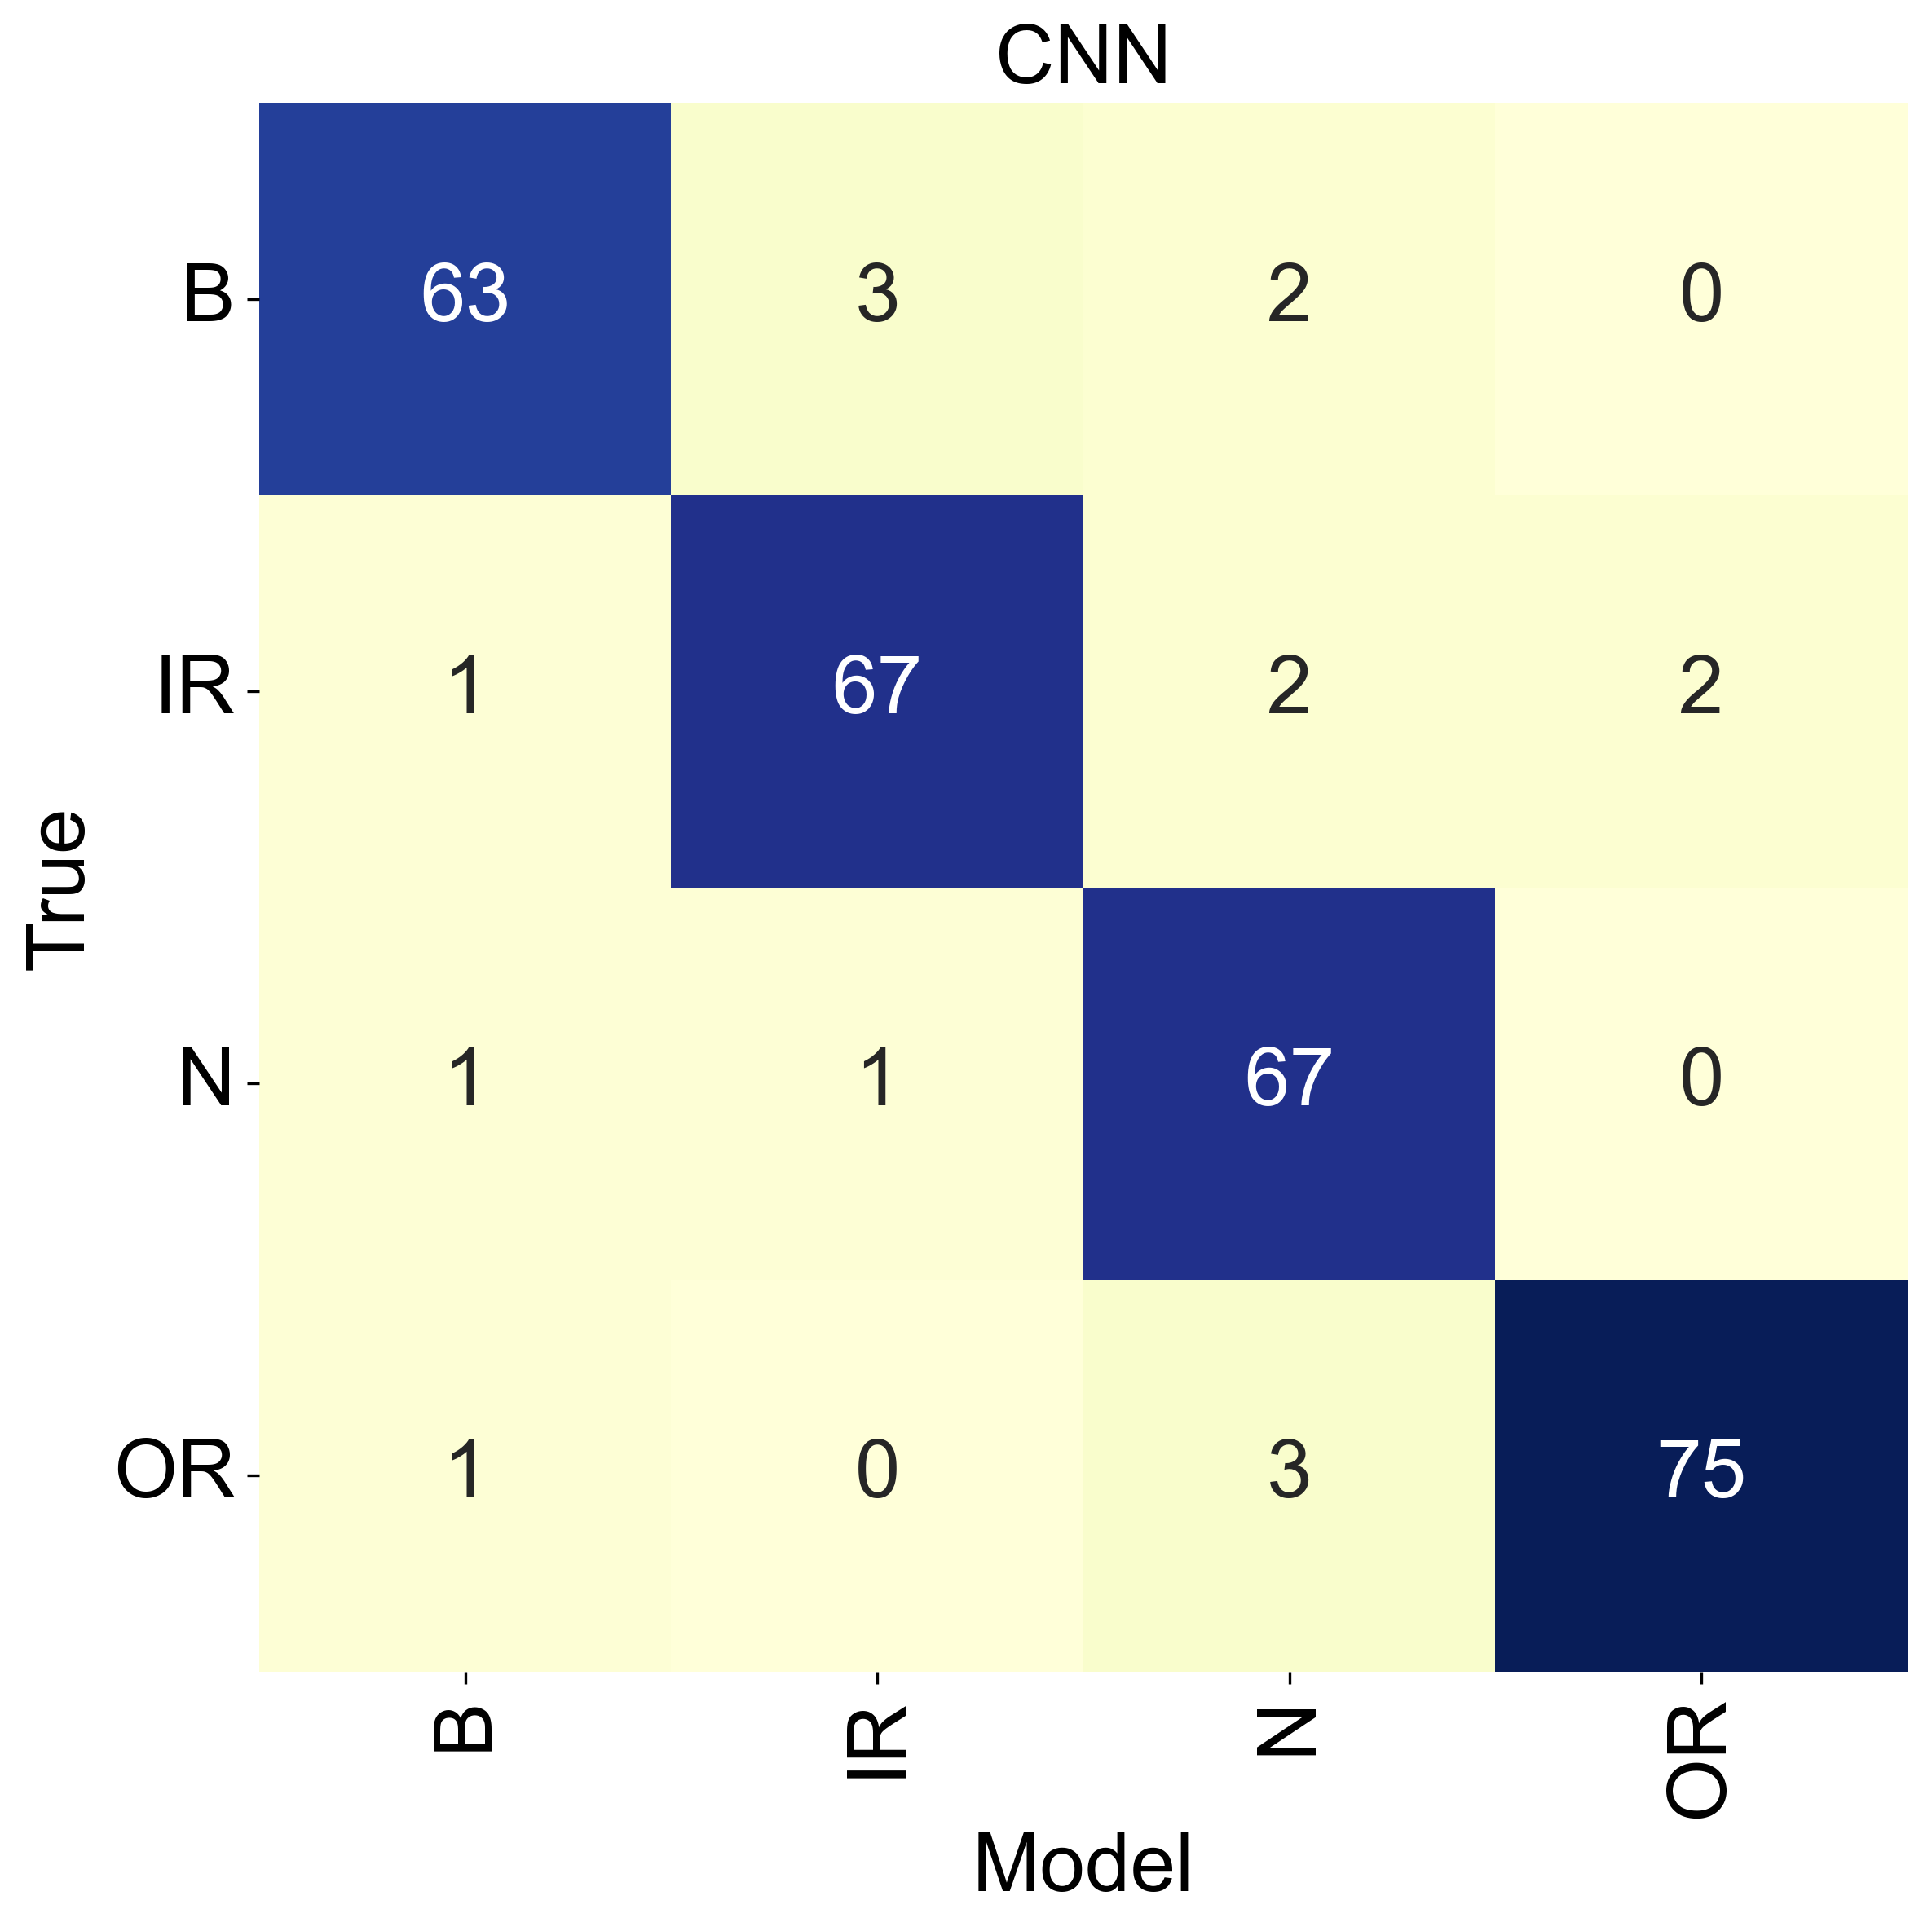

In [23]:
cm = confusion_matrix(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label)

# Plot the confusion matrix
plt.figure(figsize=(8, 8),dpi=300)
sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='g', cbar=False,
            annot_kws={"size": 24, 'fontname': 'Arial'})  # Annotation font size and font

# Adding labels and title with Arial font size 24
plt.xlabel('Model', fontsize=24, fontname='Arial')
plt.ylabel('True', fontsize=24, fontname='Arial')
plt.title('CNN', fontsize=24, fontname='Arial')
tick_labels = ['B', 'IR', 'N', 'OR']
# Adjust the tick labels to font size 24
plt.xticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=tick_labels, fontsize=24, fontname='Arial', rotation=90)
plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=tick_labels, fontsize=24, fontname='Arial', rotation=0)


# Display the plot
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import classification_report

print(classification_report(torch.argmax(torch.softmax(test_predictions, dim=1), dim=1).numpy(), test_label))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        68
           1       0.94      0.93      0.94        72
           2       0.91      0.97      0.94        69
           3       0.97      0.95      0.96        79

    accuracy                           0.94       288
   macro avg       0.94      0.94      0.94       288
weighted avg       0.95      0.94      0.94       288



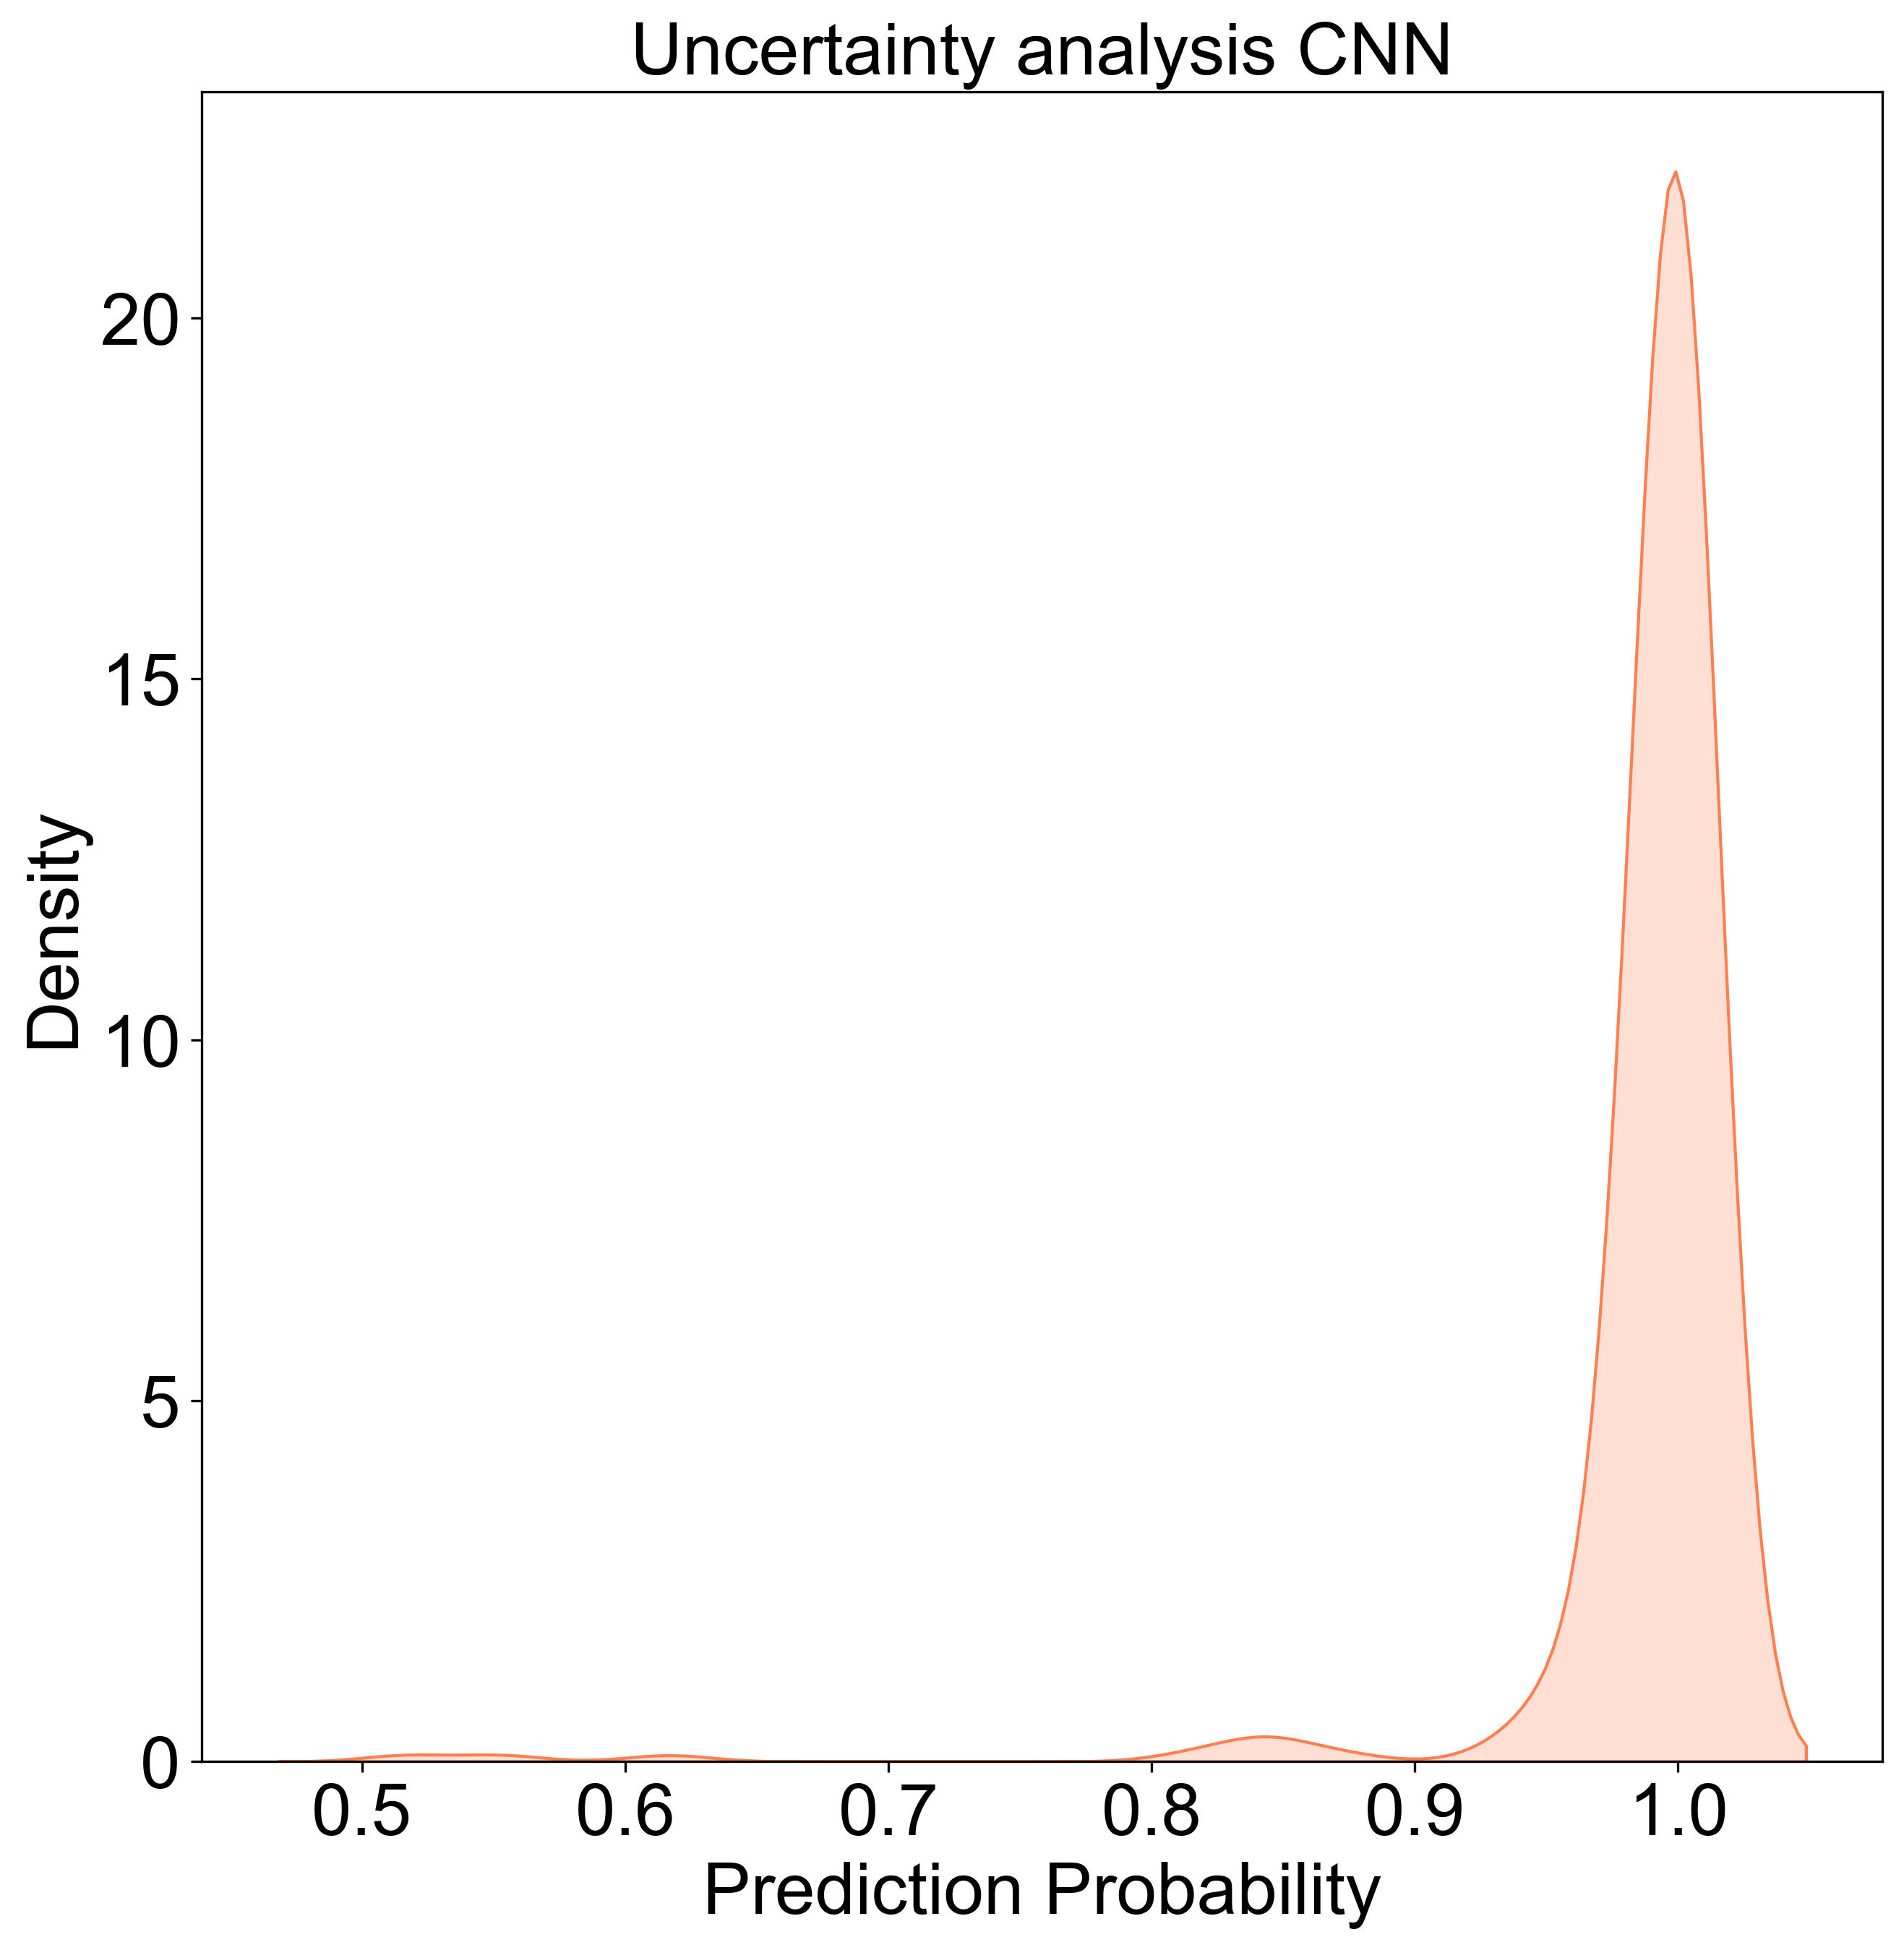

In [25]:
probabilities = np.array(torch.max(torch.softmax(test_predictions, dim=1),axis=1)[0]).tolist()
# Create KDE plot for uncertainty distribution
plt.figure(figsize=(10, 10), dpi=300)
sns.kdeplot(probabilities, color='coral', fill=True)
plt.xlabel('Prediction Probability', fontsize=24, fontname='Arial')
plt.ylabel('Density', fontsize=24, fontname='Arial')
plt.title('Uncertainty analysis CNN', fontsize=24, fontname='Arial')
plt.xticks(fontsize=24, fontname='Arial')
plt.yticks(fontsize=24, fontname='Arial')
plt.show()